1. Install dependencies

In [1]:
!pip install -q torch torchvision torchaudio
!pip install -q scikit-learn pandas matplotlib seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 86.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 73.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 59.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 13.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 111.2 MB/s eta 0:00:00


2. Upload dataset ZIP

In [2]:
from google.colab import files
uploaded = files.upload()  # upload dataset_ocr.zip

Saving dummy_ktp.zip to dummy_ktp.zip


3. Extract the zip

In [3]:
import zipfile
import os

with zipfile.ZipFile("dummy_ktp.zip", 'r') as zip_ref:
    zip_ref.extractall(".")

4. Load CSV and preprocess

In [16]:
import pandas as pd

csv_path = "dummy_ktp/dataset_split_fields.csv"
df = pd.read_csv(csv_path)
df.fillna("", inplace=True)
df['image_path'] = df['image_path'].str.replace("\\", "/", regex=False)

fields = [
    'NIK',
    'Nama',
    'Tempat/Tgl Lahir',
    'Jenis Kelamin',
    'Gol.Darah',
    'Alamat',
    'RT/RW',
    'Kel/Desa',
    'Kecamatan',
    'Agama',
    'Status Perkawinan',
    'Kewarganegaraan',
    'Berlaku Hingga'
]

# Gabungkan jadi satu string sebagai target label OCR
df['text'] = df[fields].astype(str).agg(' '.join, axis=1)

In [17]:
for idx, row in df.iterrows():
    print(f"{row['image_path']} → {row['text']}")

dummy_ktp/ktp_1.jpg → 3265389623275103 NILAM WALUYO Dumai, 31-08-1988 PEREMPUAN A GG. SURYAKENCANA 65/84 SIDODADI TAMAN HINDU CERAI MATI WNI SEUMUR HIDUP
dummy_ktp/ktp_10.jpg → 3155429551397779 MALA HANDAYANI Bandar Lampung, 08-05-1968 LAKI-LAKI B GANG SETIABUDHI 23/86 NGABAN TANGGULANGIN ISLAM BELUM KAWIN WNI SEUMUR HIDUP
dummy_ktp/ktp_11.jpg → 3818949543474329 NADINE WACANA Pekalongan, 03-11-1976 PEREMPUAN AB GG. RAJAWALI TIMUR 46/21 TEBEL GEDANGAN KATOLIK CERAI HIDUP WNI SEUMUR HIDUP
dummy_ktp/ktp_12.jpg → 3164891538893590 LUIS WINARSIH, S.H. Kota Administrasi Jakarta Selatan, 17-06-2006 LAKI-LAKI AB JL. PASTEUR 49/49 TROMPOASRI JABON KATOLIK CERAI MATI WNI SEUMUR HIDUP
dummy_ktp/ktp_13.jpg → 3168656919673907 R. AMI NAPITUPULU, S.KED Samarinda, 22-04-1988 PEREMPUAN AB GANG M.H THAMRIN 04/28 SIDODADI TAMAN ISLAM CERAI HIDUP WNI SEUMUR HIDUP
dummy_ktp/ktp_14.jpg → 3753113328717246 DR. JULIA SURYONO, M.KOM. Prabumulih, 01-04-1985 PEREMPUAN B JALAN RONGGOWARSITO 70/93 PLOSO WONOAYU HIND

5. Split train/test

In [18]:
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)

6. Create vocabulary

In [19]:
import string

VOCAB = list(string.ascii_uppercase + string.digits + ",./:;- '\"")
char_to_idx = {ch: idx+1 for idx, ch in enumerate(VOCAB)}  # 0 = blank for CTC
idx_to_char = {idx: ch for ch, idx in char_to_idx.items()}

7. Dataset and DataLoader

In [28]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

transform = transforms.Compose([
    transforms.Grayscale(),
    transforms.Resize((32, 384)),  # ubah dari (32, 128) ke (32, 256)
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])


class OCRDataset(Dataset):
    def __init__(self, df):
        self.df = df.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(row['image_path']).convert("RGB")
        img_tensor = transform(img)
        label_str = row['text'].upper()
        label_idx = [char_to_idx.get(ch, 0) for ch in label_str if ch in char_to_idx]
        return img_tensor, torch.tensor(label_idx)
# Fungsi collate untuk padding label
def collate_fn(batch):
    images, labels = zip(*batch)
    images = torch.stack(images)

    flat_labels = torch.cat(labels)
    label_lengths = torch.tensor([len(label) for label in labels], dtype=torch.long)

    return images, flat_labels, label_lengths

train_data = OCRDataset(train_df)
test_data = OCRDataset(test_df)

train_loader = DataLoader(train_data, batch_size=8, shuffle=True, collate_fn=collate_fn)
test_loader = DataLoader(test_data, batch_size=8, shuffle=False, collate_fn=lambda x: x)

# ➕ Cek maksimal panjang label
max_label_len = max([len(label) for _, label in train_data])
print(f"🔤 Max label length: {max_label_len}")

train_loader = DataLoader(train_data, batch_size=8, shuffle=True, collate_fn=collate_fn)

🔤 Max label length: 170


8. Model

In [29]:
import torch.nn as nn

class CRNN(nn.Module):
    def __init__(self, num_classes):
        super(CRNN, self).__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(1, 32, 3, 1, 1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.rnn = nn.LSTM(32*16, 128, bidirectional=True, batch_first=True)
        self.fc = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.cnn(x)
        b, c, h, w = x.size()
        x = x.permute(0, 3, 1, 2).contiguous().view(b, w, -1)
        x, _ = self.rnn(x)
        x = self.fc(x)
        return x

model = CRNN(num_classes=len(char_to_idx) + 1).to("cuda")

9. Train

In [53]:
from torch.nn import CTCLoss
import torch.optim as optim

criterion = CTCLoss(blank=0, zero_infinity=True)  # zero_infinity untuk hindari nan
optimizer = optim.Adam(model.parameters(), lr=1e-3)

def train_one_epoch():
    model.train()
    total_loss = 0
    for batch_idx, (imgs, labels, label_lens) in enumerate(train_loader):
        imgs = imgs.to("cuda")
        labels = labels.to("cuda")
        label_lens = label_lens.to("cuda")

        if any(l == 0 for l in label_lens):
            print(f"⛔ Skipping batch {batch_idx} karena ada label kosong")
            continue

        logits = model(imgs)
        log_probs = logits.log_softmax(2).permute(1, 0, 2)
        input_lens = torch.full(size=(logits.size(0),), fill_value=logits.size(1), dtype=torch.long).to("cuda")

        print(f"\n Batch {batch_idx}")
        print(f"   imgs shape        : {imgs.shape}")
        print(f"   logits shape     : {logits.shape}")
        print(f"   log_probs shape  : {log_probs.shape}")
        print(f"   labels shape     : {labels.shape}")
        print(f"   label lengths    : {label_lens.tolist()}")
        print(f"   input lengths    : {input_lens.tolist()}")

        if any(label_lens[i] > input_lens[i] for i in range(len(label_lens))):
            print(" Skip batch karena panjang label > panjang input")
            continue

        loss = criterion(log_probs, labels, input_lens, label_lens)

        if torch.isnan(loss):
            print(" Loss NaN ditemukan. Skip batch.")
            continue

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader) if len(train_loader) > 0 else 0
    print(f"✅ Train Loss: {avg_loss:.4f}")


for epoch in range(200):
    print(f"\n🔥 Epoch {epoch+1}")
    train_one_epoch()

Streaming output truncated to the last 5000 lines.
   labels shape     : torch.Size([1183])
   label lengths    : [141, 164, 148, 148, 149, 128, 166, 139]
   input lengths    : [192, 192, 192, 192, 192, 192, 192, 192]

 Batch 4
   imgs shape        : torch.Size([8, 1, 32, 384])
   logits shape     : torch.Size([8, 192, 46])
   log_probs shape  : torch.Size([192, 8, 46])
   labels shape     : torch.Size([1192])
   label lengths    : [161, 144, 140, 146, 170, 147, 132, 152]
   input lengths    : [192, 192, 192, 192, 192, 192, 192, 192]
✅ Train Loss: 1.5554

🔥 Epoch 85

 Batch 0
   imgs shape        : torch.Size([8, 1, 32, 384])
   logits shape     : torch.Size([8, 192, 46])
   log_probs shape  : torch.Size([192, 8, 46])
   labels shape     : torch.Size([1198])
   label lengths    : [152, 143, 150, 147, 161, 170, 138, 137]
   input lengths    : [192, 192, 192, 192, 192, 192, 192, 192]

 Batch 1
   imgs shape        : torch.Size([8, 1, 32, 384])
   logits shape     : torch.Size([8, 192, 46

10. Save model

In [35]:
torch.save(model.state_dict(), "ocr_crnn_ctc.pth")
print("✅ Model saved")

✅ Model saved


In [54]:
torch.save(model.state_dict(), "ocr_crnn_ctc.pt")
print("✅ Model saved")

✅ Model saved


11. Evaluasi

In [70]:
# Tampilkan 5 hasil prediksi pertama
for i, pred in enumerate(all_preds[:5]):
    print(f"Prediksi {i+1}: {pred}")

Prediksi 1: 3533233327440 ZALAI ATAO PANGAG, 25-0-1 PEREMPUAN JL. W. AN 6/2 PAAN AN KIUDHU CERAI HIDUP WNI SEUMUR HIDUP
Prediksi 2: 346832388370 LANS WAI KTA AMINISTASJKA SEATR, 0-0-19 LAKI-LAN . SDEAN 5/4 SAOPN RKAI KITAK CERAI HADUP WNI SEUMUR HIDUP
Prediksi 3: 3536283223346 DR. TADA UPIAI, S.P PUON, 0-4-198 AKI-LA JA AUI /86 ADN AON KIUDLI CERAI KAWIN WNI SEUMUR HIDUP
Prediksi 4: 3464888227346 DR. HATATISAI, SKR ILA, 2-19EMUAN AJ. AJA 3/4 KAN SI IKA SAY KTHAK CERAM KAWUP WNI SEUMUR HIDUP
Prediksi 5: 3536283227346 DR. AINA SUPTA, S.A SIAIA, 2-0-1987 PEMUAK A A A WA TAN 6/ KAN KAON KITOLAK KEAI KAWIN WNI SEUMUR HIDUP


In [38]:
 pip install jiwer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 38.7 MB/s eta 0:00:00


In [55]:
import torch.nn.functional as F
from tqdm import tqdm
from jiwer import wer, cer  # install: pip install jiwer

def decode_prediction(logits, idx_to_char):
    pred_idxs = logits.argmax(2)  # ambil index tertinggi [B, T]
    pred_texts = []
    for pred in pred_idxs:
        chars = []
        prev_idx = -1
        for idx in pred:
            if idx.item() != prev_idx and idx.item() != 0:
                chars.append(idx_to_char.get(idx.item(), ""))
            prev_idx = idx.item()
        pred_texts.append("".join(chars))
    return pred_texts

model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for batch in tqdm(test_loader):
        imgs, labels = zip(*batch)
        imgs = torch.stack(imgs).to("cuda")
        label_texts = []
        for label in labels:
            label_texts.append("".join([idx_to_char[idx.item()] for idx in label]))

        logits = model(imgs)
        log_probs = logits.log_softmax(2).permute(1, 0, 2)
        preds = decode_prediction(log_probs.permute(1, 0, 2), idx_to_char)

        all_preds.extend(preds)
        all_labels.extend(label_texts)

# 🔥 Akurasi karakter dan kata
cer_score = cer(all_labels, all_preds)
wer_score = wer(all_labels, all_preds)

print(f"📉 Character Error Rate (CER): {cer_score:.4f}")
print(f"📉 Word Error Rate (WER): {wer_score:.4f}")

100%|██████████| 2/2 [00:00<00:00, 13.69it/s]

📉 Character Error Rate (CER): 0.5221
📉 Word Error Rate (WER): 0.8051


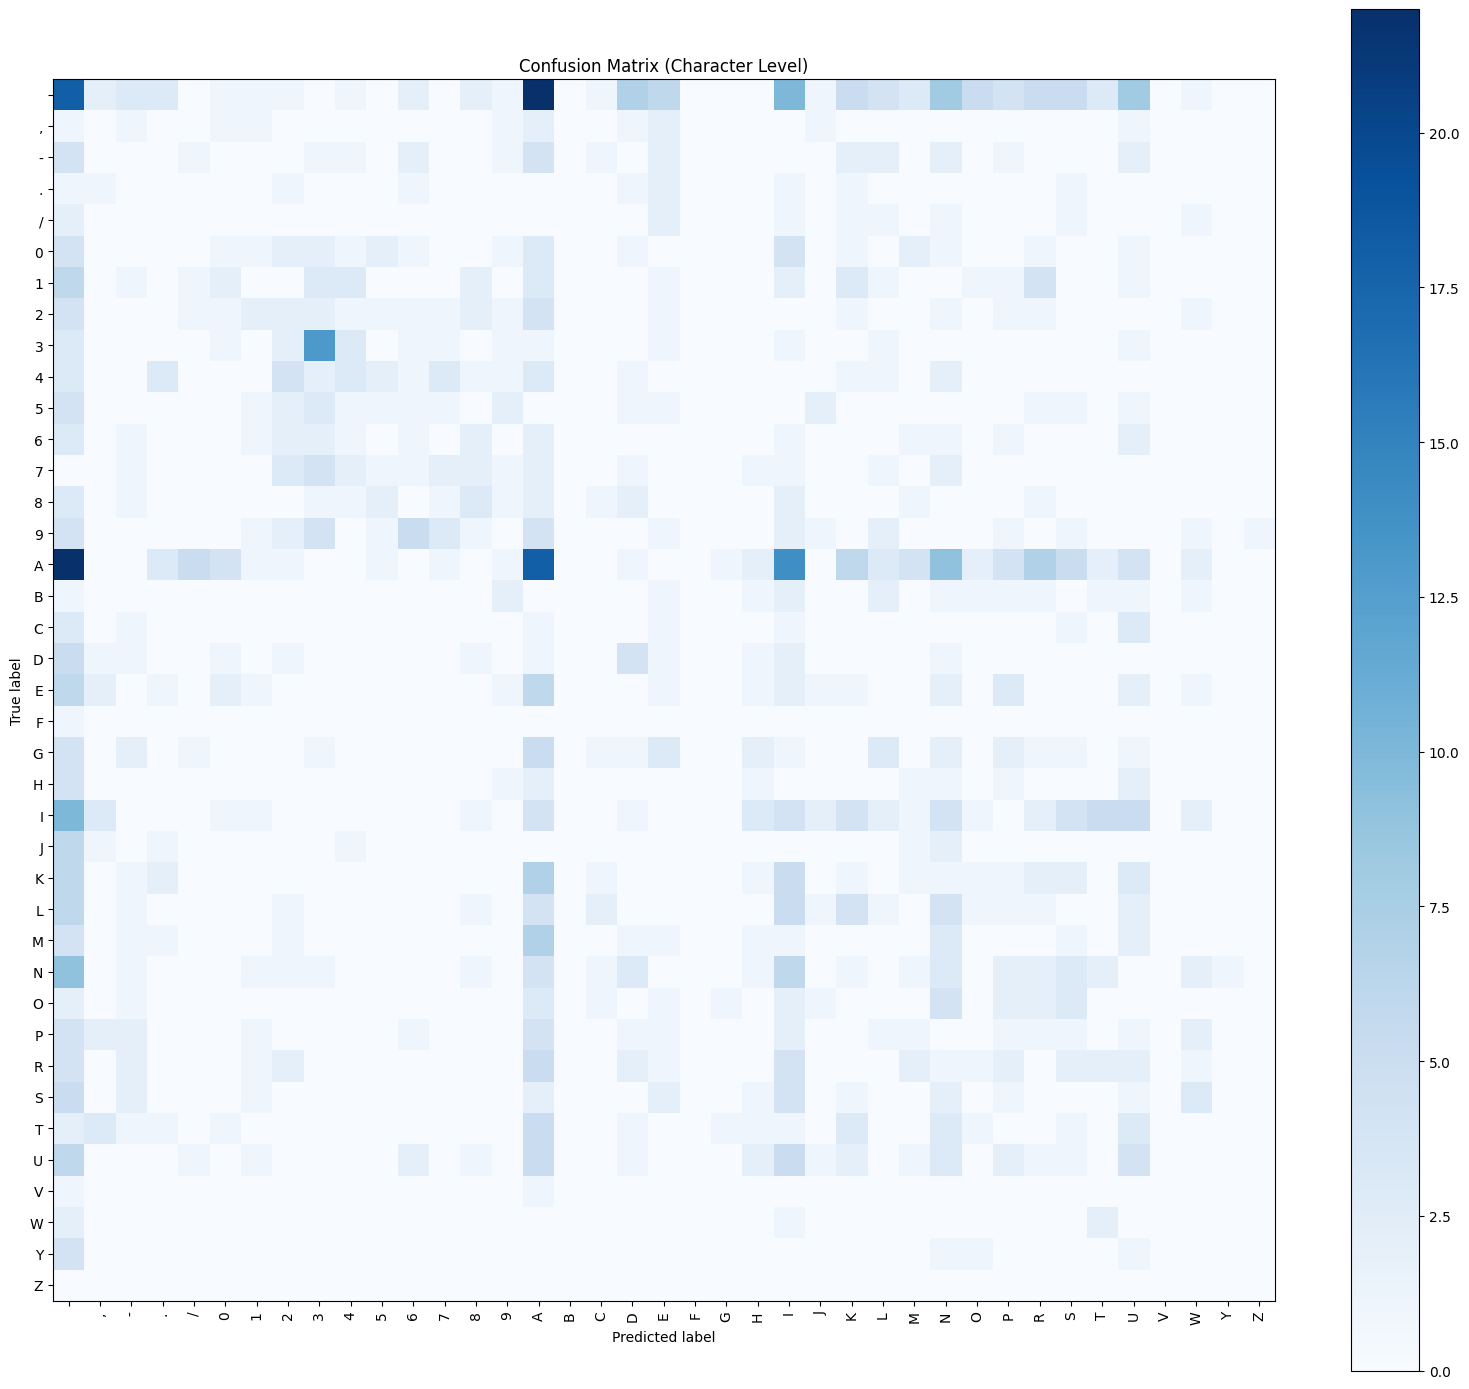

In [58]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Ambil karakter unik dari semua prediksi dan label
all_chars = sorted(set("".join(all_labels + all_preds)))
char_to_idx = {char: idx for idx, char in enumerate(all_chars)}

# Potong prediksi dan label agar panjangnya sama
y_true = []
y_pred = []

for label, pred in zip(all_labels, all_preds):
    min_len = min(len(label), len(pred))
    y_true.extend([char_to_idx[c] for c in label[:min_len]])
    y_pred.extend([char_to_idx[c] for c in pred[:min_len]])

# Hitung confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=range(len(all_chars)))

# Tampilkan
fig, ax = plt.subplots(figsize=(16, 14))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=all_chars)
disp.plot(include_values=False, cmap="Blues", ax=ax, xticks_rotation="vertical", colorbar=True)
plt.title("Confusion Matrix (Character Level)")
plt.grid(False)
plt.tight_layout()
plt.show()


In [59]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Hitung metrik evaluasi karakter-level
precision = precision_score(y_true, y_pred, average='macro', zero_division=0)
recall = recall_score(y_true, y_pred, average='macro', zero_division=0)
f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)

print(f"🎯 Precision (char-level): {precision:.4f}")
print(f"🔁 Recall (char-level): {recall:.4f}")
print(f"📊 F1 Score (char-level): {f1:.4f}")

🎯 Precision (char-level): 0.0457
🔁 Recall (char-level): 0.0477
📊 F1 Score (char-level): 0.0452


In [60]:
from sklearn.metrics import classification_report

# Buat label nama karakter untuk laporan
target_names = [f"'{char}'" for char in all_chars]  # misalnya 'A', 'B', 'C', ...

# Cetak classification report
print("📋 Classification Report (Character Level):\n")
print(classification_report(y_true, y_pred, target_names=target_names, zero_division=0))

📋 Classification Report (Character Level):

              precision    recall  f1-score   support

         ' '       0.10      0.14      0.12       133
         ','       0.00      0.00      0.00        12
         '-'       0.00      0.00      0.00        26
         '.'       0.00      0.00      0.00        10
         '/'       0.00      0.00      0.00        10
         '0'       0.06      0.03      0.04        29
         '1'       0.00      0.00      0.00        35
         '2'       0.07      0.07      0.07        29
         '3'       0.33      0.43      0.38        30
         '4'       0.16      0.10      0.12        31
         '5'       0.09      0.04      0.06        23
         '6'       0.05      0.05      0.05        21
         '7'       0.15      0.08      0.11        25
         '8'       0.15      0.14      0.14        22
         '9'       0.00      0.00      0.00        35
         'A'       0.13      0.15      0.14       123
         'B'       0.00      0.00    

In [63]:
from sklearn.metrics import classification_report
import numpy as np

# Set karakter yang diizinkan
allowed_chars = set("ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789")

# Reverse mapping index ke char
idx_to_char_rev = {v: k for k, v in char_to_idx.items()}

# Simpan pasangan valid
y_true_filtered = []
y_pred_filtered = []

for yt, yp in zip(y_true, y_pred):
    ch_true = idx_to_char_rev[yt]
    ch_pred = idx_to_char_rev[yp]
    if ch_true in allowed_chars and ch_pred in allowed_chars:
        y_true_filtered.append(ch_true)
        y_pred_filtered.append(ch_pred)

# Ambil semua karakter unik yang muncul
used_chars = sorted(set(y_true_filtered + y_pred_filtered))
char_to_index = {ch: idx for idx, ch in enumerate(used_chars)}

# Konversi ke indeks sesuai label yang benar-benar muncul
y_true_final = [char_to_index[ch] for ch in y_true_filtered]
y_pred_final = [char_to_index[ch] for ch in y_pred_filtered]

# Cetak classification report
print("📋 Classification Report (A-Z, 0-9 only):\n")
print(classification_report(
    y_true_final, y_pred_final,
    labels=list(range(len(used_chars))),
    target_names=used_chars,
    zero_division=0
))

📋 Classification Report (A-Z, 0-9 only):

              precision    recall  f1-score   support

           0       0.07      0.04      0.05        25
           1       0.00      0.00      0.00        27
           2       0.08      0.08      0.08        24
           3       0.34      0.48      0.40        27
           4       0.18      0.12      0.14        25
           5       0.09      0.05      0.07        19
           6       0.07      0.06      0.06        17
           7       0.15      0.08      0.11        24
           8       0.17      0.17      0.17        18
           9       0.00      0.00      0.00        31
           A       0.17      0.19      0.18        93
           B       0.00      0.00      0.00        15
           C       0.00      0.00      0.00         7
           D       0.18      0.31      0.23        13
           E       0.06      0.04      0.05        24
           G       0.00      0.00      0.00        24
           H       0.05      0.11      

<ipython-input-66-3c3bd19646ec>:21: UserWarning: Glyph 128288 (\N{INPUT SYMBOL FOR LATIN CAPITAL LETTERS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128288 (\N{INPUT SYMBOL FOR LATIN CAPITAL LETTERS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


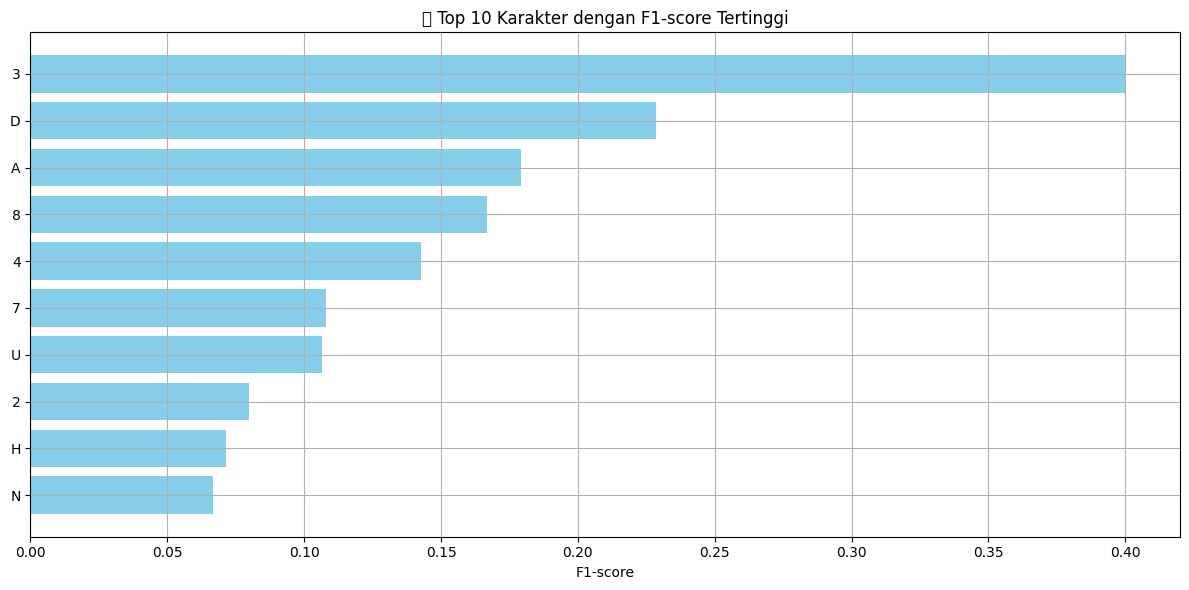

In [66]:
from sklearn.metrics import precision_recall_fscore_support
import matplotlib.pyplot as plt
import numpy as np

precision, recall, f1, support = precision_recall_fscore_support(
    y_true_final, y_pred_final,
    labels=list(range(len(used_chars))),
    zero_division=0
)

# Visualisasi F1-score
f1_sorted_idx = np.argsort(f1)
top_n = 10

plt.figure(figsize=(12, 6))
plt.barh(range(top_n), np.array(f1)[f1_sorted_idx][-top_n:], color='skyblue')
plt.yticks(range(top_n), [used_chars[i] for i in f1_sorted_idx[-top_n:]])
plt.xlabel("F1-score")
plt.title("🔠 Top 10 Karakter dengan F1-score Tertinggi")
plt.grid(True)
plt.tight_layout()
plt.show()


<ipython-input-67-4a8bc59d3954>:25: UserWarning: Glyph 128315 (\N{DOWN-POINTING RED TRIANGLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128315 (\N{DOWN-POINTING RED TRIANGLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


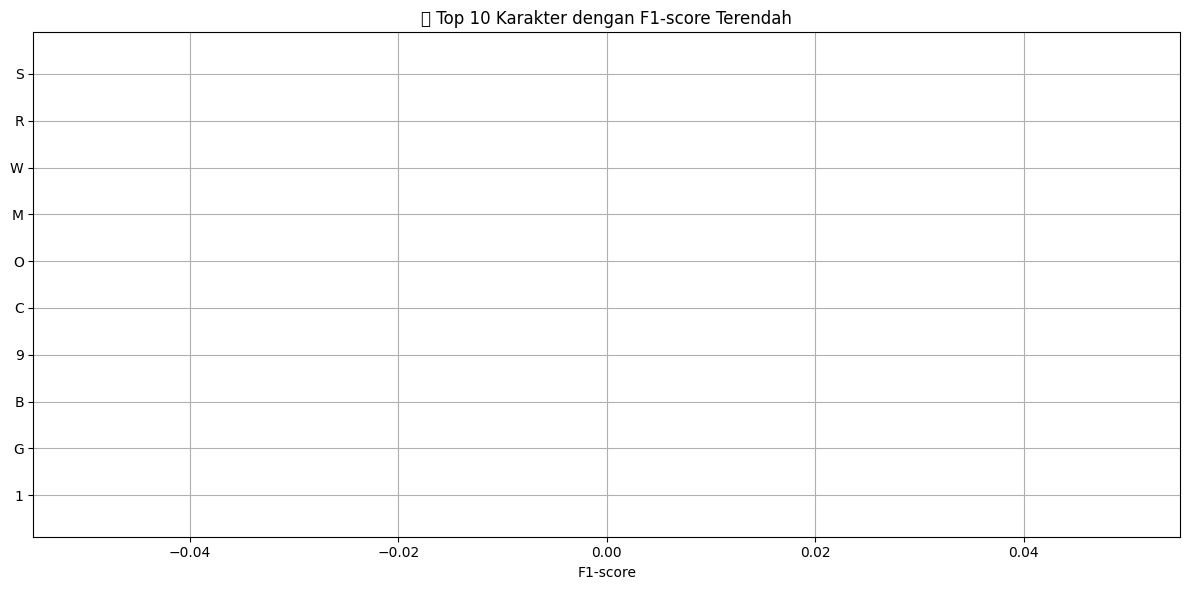

In [67]:
from sklearn.metrics import precision_recall_fscore_support
import matplotlib.pyplot as plt
import numpy as np

precision, recall, f1, support = precision_recall_fscore_support(
    y_true_final, y_pred_final,
    labels=list(range(len(used_chars))),
    zero_division=0
)

# Visualisasi F1-score
f1_sorted_idx = np.argsort(f1)
bottom_n = 10

plt.figure(figsize=(12, 6))
plt.barh(
    range(bottom_n),
    np.array(f1)[f1_sorted_idx[:bottom_n]],
    color='salmon'
)
plt.yticks(range(bottom_n), [used_chars[i] for i in f1_sorted_idx[:bottom_n]])
plt.xlabel("F1-score")
plt.title("🔻 Top 10 Karakter dengan F1-score Terendah")
plt.grid(True)
plt.tight_layout()
plt.show()

In [68]:
from sklearn.metrics import precision_score, recall_score, f1_score

fields = [
    'NIK', 'Nama', 'Tempat/Tgl Lahir', 'Jenis Kelamin', 'Gol.Darah', 'Alamat',
    'RT/RW', 'Kel/Desa', 'Kecamatan', 'Agama', 'Status Perkawinan',
    'Kewarganegaraan', 'Berlaku Hingga'
]

# Pecah hasil prediksi & label menjadi list of fields
split_labels = [x.split(maxsplit=12) for x in all_labels]
split_preds = [x.split(maxsplit=12) for x in all_preds]

print("📋 Classification Report per Field KTP:\n")
print(f"{'Field':20} {'Precision':>10} {'Recall':>10} {'F1-Score':>10}")

for i, field in enumerate(fields):
    gt_field = [row[i] if len(row) > i else "" for row in split_labels]
    pred_field = [row[i] if len(row) > i else "" for row in split_preds]

    # Hitung metrik
    precision = precision_score(gt_field, pred_field, average='micro', zero_division=0)
    recall = recall_score(gt_field, pred_field, average='micro', zero_division=0)
    f1 = f1_score(gt_field, pred_field, average='micro', zero_division=0)

    print(f"{field:20} {precision:10.2f} {recall:10.2f} {f1:10.2f}")


📋 Classification Report per Field KTP:

Field                 Precision     Recall   F1-Score
NIK                        0.00       0.00       0.00
Nama                       0.00       0.00       0.00
Tempat/Tgl Lahir           0.00       0.00       0.00
Jenis Kelamin              0.00       0.00       0.00
Gol.Darah                  0.00       0.00       0.00
Alamat                     0.30       0.30       0.30
RT/RW                      0.00       0.00       0.00
Kel/Desa                   0.00       0.00       0.00
Kecamatan                  0.00       0.00       0.00
Agama                      0.00       0.00       0.00
Status Perkawinan          0.00       0.00       0.00
Kewarganegaraan            0.00       0.00       0.00
Berlaku Hingga             0.00       0.00       0.00


<ipython-input-69-c369630ba049>:42: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


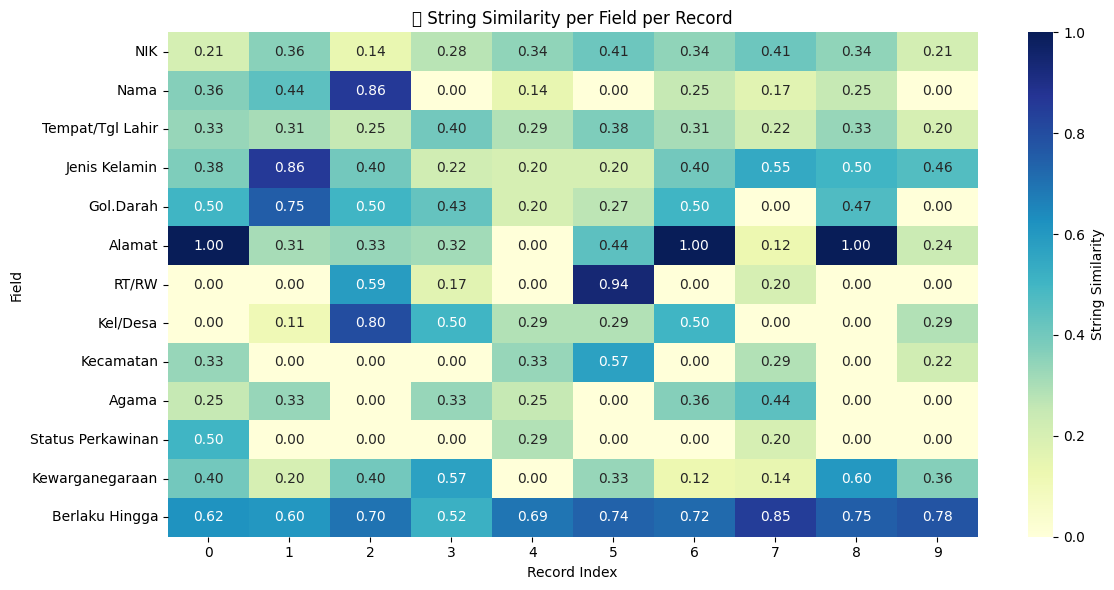

In [69]:
import difflib
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

fields = [
    'NIK', 'Nama', 'Tempat/Tgl Lahir', 'Jenis Kelamin', 'Gol.Darah', 'Alamat',
    'RT/RW', 'Kel/Desa', 'Kecamatan', 'Agama', 'Status Perkawinan',
    'Kewarganegaraan', 'Berlaku Hingga'
]

# 1. Split all_labels dan all_preds
split_labels = [x.split(maxsplit=12) for x in all_labels]
split_preds = [x.split(maxsplit=12) for x in all_preds]

# 2. Hitung similarity per field
similarity_scores = []
comparison_rows = []

for label_row, pred_row in zip(split_labels, split_preds):
    sim_row = {}
    comp_row = {}
    for i, field in enumerate(fields):
        true_val = label_row[i] if i < len(label_row) else ""
        pred_val = pred_row[i] if i < len(pred_row) else ""
        sim = difflib.SequenceMatcher(None, true_val, pred_val).ratio()
        sim_row[field] = sim
        comp_row[f'{field}_true'] = true_val
        comp_row[f'{field}_pred'] = pred_val
    similarity_scores.append(sim_row)
    comparison_rows.append(comp_row)

df_similarity = pd.DataFrame(similarity_scores)
df_comparison = pd.DataFrame(comparison_rows)

# 3. Tampilkan heatmap
plt.figure(figsize=(12, 6))
sns.heatmap(df_similarity.T, annot=True, cmap='YlGnBu', fmt=".2f", cbar_kws={'label': 'String Similarity'})
plt.title("📊 String Similarity per Field per Record")
plt.ylabel("Field")
plt.xlabel("Record Index")
plt.tight_layout()
plt.show()

# 4. Simpan CSV perbandingan
df_comparison.to_csv("field_comparison_ktp.csv", index=False)